## 概要

『マーケティングサイエンスの理論と実践』第9章「売上の変動を分解して予測する」の内容を紹介する。売上の増加を施策の成果と判断する前に、長期傾向や季節性を確認するための記事である。本文と同じく、前後比較の問題、Prophet、状態空間モデル、Pythonによる実装の順に扱う。

予測値だけでなく、売上の水準、傾き、季節性、予測の不確かさを図で確認する。コードは模擬データから実行できる。

## 実行環境

カーネルは **wa-src(3.14.6)**、Pythonは **3.14.6** である。NumPy、SciPy、pandas、Matplotlib、Prophet、statsmodels、matplotlib-fontjaを使う。バージョンは次の出力に示す。セルを上から実行すると、図をノートブック内に表示し、`09_nb_files`にもSVG形式で保存する。表示する小数は有効数字3桁とし、計算では丸めない。

In [1]:
import logging
import platform
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib_fontja  # 日本語の描画用フォントを設定する。
import numpy as np
import pandas as pd
from IPython.display import Latex, SVG, display
from matplotlib.ticker import FuncFormatter
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.statespace.structural import UnobservedComponents

# この例は静的なSVGを使うため、任意のPlotly機能の通知を省く。
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
from prophet import Prophet

print(f"実行環境: wa-src(3.14.6) / Python {platform.python_version()}")
for package in ["numpy", "scipy", "pandas", "matplotlib", "prophet",
                "statsmodels", "matplotlib-fontja"]:
    print(f"{package}: {version(package)}")


def sig3(value):
    """末尾の0も残して有効数字3桁で表示する。"""
    return f"{float(value):#.3g}"


np.set_printoptions(formatter={"float_kind": sig3})
pd.options.display.float_format = sig3
plt.rcParams.update({
    "figure.figsize": (10, 4), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.250,
    "svg.fonttype": "path", "svg.hashsalt": "blog09",
})
BLUE, ORANGE, GRAY = "#245b86", "#b85d28", "#767676"

# リポジトリ直下から実行する場合も、保存先をblog/09配下にそろえる。
base = Path("blog/09") if Path("blog/09/09_nb.ipynb").exists() else Path.cwd()
figure_dir = base / "09_nb_files"
figure_dir.mkdir(parents=True, exist_ok=True)


def save_svg(fig, name):
    """図をSVGで保存し、同じSVGを出力欄に埋め込む。"""
    for ax in fig.axes:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
    fig.tight_layout()
    path = figure_dir / name
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    display(SVG(filename=str(path)))
    plt.close(fig)


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

実行環境: wa-src(3.14.6) / Python 3.14.6
numpy: 2.4.6
scipy: 1.18.1
pandas: 2.3.3
matplotlib: 3.11.2
prophet: 1.3.0
statsmodels: 0.14.6
matplotlib-fontja: 1.1.0


## 1. 売上を成分に分ける理由

クーポン配布週の売上が前週比18％増でも、前年の同時期に15％増えていれば、季節性が関係した可能性がある。差の3ポイントも、価格や競合状況が異なる以上、そのまま施策の効果とはいえない。

売上$y_t$を、水準$\mu_t$、季節性$s_t$、施策などと結び付く成分$x_t$、ノイズ$\varepsilon_t$に分ける。前日の式を引くと、前後比較に何が混ざるかがわかる。

<div>

$$
\begin{aligned}
y_t&=\mu_t+s_t+x_t+\varepsilon_t,\\
y_{t-1}&=\mu_{t-1}+s_{t-1}+x_{t-1}+\varepsilon_{t-1},\\
\Delta y_t&=y_t-y_{t-1}\\
&=\Delta\mu_t+\Delta s_t+\Delta x_t+\Delta\varepsilon_t.
\end{aligned}
$$

</div>

観測値の増減と、基礎的な売上水準の変化も同じではない。私は、単日の増減を説明する前に、前後の推移を図で確認することが大切だと考える。

## 2. Prophetによる成分分解

Prophetの加法モデルは、トレンド$g(t)$、季節性$s(t)$、登録した祝日・イベントの成分$h(t)$を足し合わせる。季節性は周期$P$の波を$N$組重ねて表す。

<div>

$$
\begin{aligned}
y(t)&=g(t)+s(t)+h(t)+\varepsilon_t,\\
s(t)&=\sum_{n=1}^{N}\left[a_n\cos\left(\frac{2\pi nt}{P}\right)
+b_n\sin\left(\frac{2\pi nt}{P}\right)\right],\\
h(t)&=\mathbf{z}(t)^\top\mathbf{b}_h.
\end{aligned}
$$

</div>

$\mathbf{z}(t)$はイベントの有無、$\mathbf{b}_h$はその係数を並べたベクトルである。週次なら$P=7$となる。トレンドは変化点で傾きが変わる折れ線などで表す。欠測日を無理に埋めずに扱え、祝日や変化点を設定できるが、成分分解だけで施策の因果効果を確かめることはできない。

## 3. 状態空間モデルで水準と傾きを推定する

ローカルレベルモデルは、観測値と潜在的な水準を分ける。観測ノイズ$\varepsilon_t$はその日のばらつき、状態ノイズ$\eta_t$は以後にも残る水準の変化である。ここでは各ノイズを時点間でも互いにも独立とする。

<div>

$$
\begin{aligned}
y_t&=\mu_t+\varepsilon_t,&\varepsilon_t&\sim\mathcal N(0,r),\\
\mu_t&=\mu_{t-1}+\eta_t,&\eta_t&\sim\mathcal N(0,q).
\end{aligned}
$$

</div>

信号対雑音比$q/r$が小さいほど、水準は滑らかに推定されやすい。ローカル線形トレンドモデルでは傾き$\nu_t$を追加する。状態ベクトルを$\mathbf{u}_t=(\mu_t,\nu_t)^\top$と置くと、行列の掛け算は次の2本の式になる。

<div>

$$
\begin{aligned}
\mathbf{u}_t
&=\begin{pmatrix}1&1\\0&1\end{pmatrix}\mathbf{u}_{t-1}
+\begin{pmatrix}\eta_t\\\zeta_t\end{pmatrix}\\
&=\begin{pmatrix}\mu_{t-1}+\nu_{t-1}+\eta_t\\\nu_{t-1}+\zeta_t\end{pmatrix}.
\end{aligned}
$$

</div>

### カルマンフィルタの計算

ローカルレベルモデルで、前日の推定平均を$a_{t-1}$、分散を$P_{t-1}$とする。まず観測前の平均$a_t^-$と分散$P_t^-$を予測し、観測値との差$v_t$を重み$K_t$で取り込む。

<div>

$$
\begin{aligned}
a_t^-&=a_{t-1},&P_t^-&=P_{t-1}+q,\\
v_t&=y_t-a_t^-,&K_t&=\frac{P_t^-}{P_t^-+r},\\
a_t&=a_t^-+K_tv_t=(1-K_t)a_t^-+K_ty_t,\\
P_t&=(1-K_t)P_t^-=\frac{rP_t^-}{P_t^-+r}.
\end{aligned}
$$

</div>

観測ノイズ$r$が大きいほど観測値の重みは小さくなる。当日までの観測で推定するのがフィルタリング、全期間の観測で過去を推定し直すのがスムージングである。後者を当時の予測として評価してはいけない。

## 4. Pythonによる実装

### 4.1 Prophetで365日先まで予測する

本文の例と同じく、2022～2024年の日次データを作る。1日500円の上昇、年次・週次季節性、標準偏差8万円のノイズを加える。これは冒頭のクーポン事例の実測値ではなく、祝日や施策の効果も含まない。

        ds      y
2022-01-01 739737
2022-01-02 767666
2022-01-03 850485
2022-01-04 867130
2022-01-05 640589


/var/folders/3y/fmw40k0x78xblvb3gkcyvy1h0000gn/T/ipykernel_97239/1775162875.py:54: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.tight_layout()
/var/folders/3y/fmw40k0x78xblvb3gkcyvy1h0000gn/T/ipykernel_97239/1775162875.py:56: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})


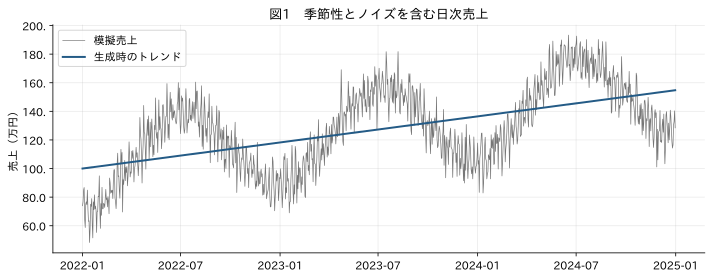

In [2]:
# 元ノートブックと同じ乱数系列と生成条件を使う。
dates = pd.date_range("2022-01-01", "2024-12-31", freq="D")
t = np.arange(len(dates))
random_prophet = np.random.RandomState(42)
trend = 1_000_000 + 500 * t
yearly = 300_000 * np.sin(2 * np.pi * t / (1461 / 4) - np.pi / 2)
weekly = 100_000 * np.sin(2 * np.pi * t / 7)
noise = random_prophet.normal(0, 80_000, len(t))
sales = np.maximum(trend + yearly + weekly + noise, 0).astype(int)
data = pd.DataFrame({"ds": dates, "y": sales})
print(data.head().to_string(index=False))

fig, ax = plt.subplots()
ax.plot(dates, sales / 10_000, color=GRAY, lw=0.700, label="模擬売上")
ax.plot(dates, trend / 10_000, color=BLUE, lw=2, label="生成時のトレンド")
ax.set(title="図1　季節性とノイズを含む日次売上", ylabel="売上（万円）")
ax.legend(loc="upper left")
date_axis(ax)
save_svg(fig, "01_sales.svg")

入力列は日付`ds`と売上`y`である。2024年10～12月の92日を検証用に残す。検証用モデルと、全期間で学習して2025年を予測するモデルを別々に作る。日本の祝日は、本文の設定例として追加する。

02:07:43 - cmdstanpy - INFO - Chain [1] start processing


02:07:44 - cmdstanpy - INFO - Chain [1] done processing


02:07:45 - cmdstanpy - INFO - Chain [1] start processing


02:07:45 - cmdstanpy - INFO - Chain [1] done processing


学習: 1004日 / 検証: 92日 / 将来予測: 365日


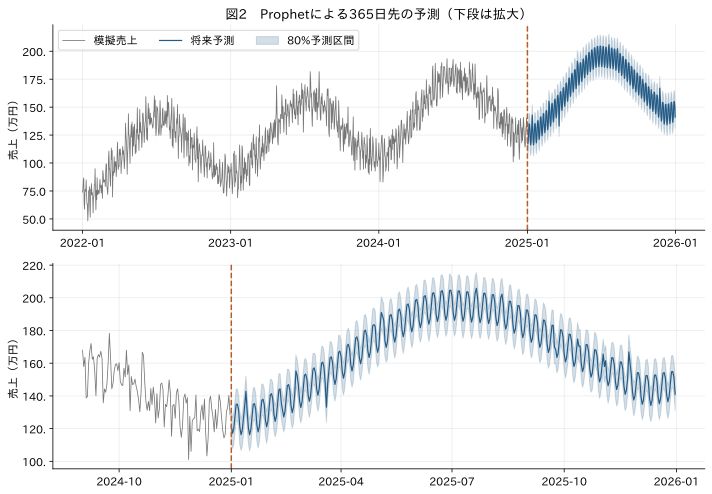

In [3]:
def make_prophet():
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=0.0500,
        seasonality_prior_scale=10,
        holidays_prior_scale=10,
        interval_width=0.800,
    )
    model.add_country_holidays(country_name="JP")
    return model


train = data.loc[data["ds"] < "2024-10-01"].copy()
test = data.loc[data["ds"] >= "2024-10-01"].copy()
evaluation_model = make_prophet().fit(train, seed=42)
final_model = make_prophet().fit(data, seed=42)

# 予測区間のシミュレーションにも乱数シードを指定する。
np.random.seed(42)
future = final_model.make_future_dataframe(periods=365, freq="D")
forecast = final_model.predict(future)
future_forecast = forecast.loc[forecast["ds"] > dates[-1]].copy()
print(f"学習: {len(train)}日 / 検証: {len(test)}日 / 将来予測: {len(future_forecast)}日")

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for ax, start in zip(axes, ["2022-01-01", "2024-09-01"]):
    observed = data.loc[data["ds"] >= start]
    ax.plot(observed["ds"], observed["y"] / 10_000,
            color=GRAY, lw=0.800, label="模擬売上")
    ax.plot(future_forecast["ds"], future_forecast["yhat"] / 10_000,
            color=BLUE, lw=1.20, label="将来予測")
    ax.fill_between(future_forecast["ds"],
                    future_forecast["yhat_lower"] / 10_000,
                    future_forecast["yhat_upper"] / 10_000,
                    color=BLUE, alpha=0.200, label="80%予測区間")
    ax.axvline(pd.Timestamp("2025-01-01"), color=ORANGE, ls="--")
    ax.set_ylabel("売上（万円）")
    date_axis(ax)
axes[0].set_title("図2　Prophetによる365日先の予測（下段は拡大）")
axes[0].legend(ncol=3, loc="upper left")
save_svg(fig, "02_prophet_forecast.svg")

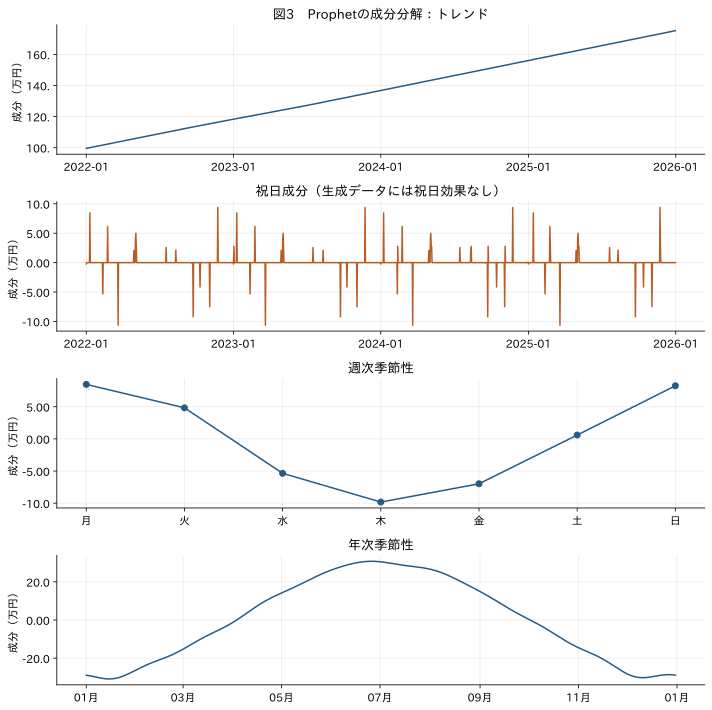

In [4]:
# 成分の図は全期間で学習したモデルの結果であり、精度検証とは分ける。
fig, axes = plt.subplots(4, 1, figsize=(10, 10))
axes[0].plot(forecast["ds"], forecast["trend"] / 10_000, color=BLUE)
axes[0].set_title("図3　Prophetの成分分解：トレンド")
axes[1].plot(forecast["ds"], forecast["holidays"] / 10_000, color=ORANGE)
axes[1].set_title("祝日成分（生成データには祝日効果なし）")
for ax in axes[:2]:
    date_axis(ax)

week = forecast.loc[forecast["ds"].between("2024-01-01", "2024-01-07")]
axes[2].plot(np.arange(7), week["weekly"] / 10_000, "o-", color=BLUE)
axes[2].set_xticks(np.arange(7), list("月火水木金土日"))
axes[2].set_title("週次季節性")
year = forecast.loc[forecast["ds"].between("2024-01-01", "2024-12-31")]
axes[3].plot(year["ds"], year["yearly"] / 10_000, color=BLUE)
axes[3].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%m月"))
axes[3].set_title("年次季節性")
for ax in axes:
    ax.set_ylabel("成分（万円）")
save_svg(fig, "03_prophet_components.svg")

図3では上昇トレンドと夏に高い季節性が見える。祝日成分に値が現れても、生成時に祝日効果を入れていないため、実際の祝日効果を示す結果ではない。

予測精度は未学習の92日で確かめる。誤差$e_i=y_i-\hat y_i$からRMSEとMAPEを計算し、80％予測区間の実際の被覆率も調べる。MAPEは売上が0のとき定義できないため、この例では正の売上であることを確認する。

<IPython.core.display.Latex object>

{'RMSE（円）': '7.31e+04', 'MAPE（%）': '4.34', '80%予測区間の被覆率（%）': '82.6'}


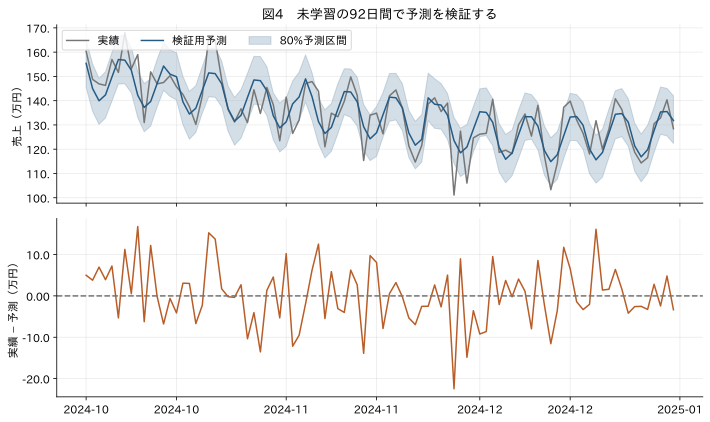

In [5]:
np.random.seed(42)
validation = evaluation_model.predict(test[["ds"]])
actual = test["y"].to_numpy()
estimate = validation["yhat"].to_numpy()
error = actual - estimate
assert np.all(actual > 0)
rmse = np.sqrt(np.mean(error ** 2))
mape = 100 * np.mean(np.abs(error) / actual)
covered = ((actual >= validation["yhat_lower"].to_numpy())
           & (actual <= validation["yhat_upper"].to_numpy()))
coverage = 100 * covered.mean()

# 重要な式は \( ... \) のLaTeXとして出力欄に表示する。
display(Latex(
    r"\(\displaystyle \begin{aligned}"
    r"\mathrm{RMSE}&=\sqrt{\frac{1}{n}\sum_{i=1}^{n}e_i^2},\\"
    r"\mathrm{MAPE}&=\frac{100}{n}\sum_{i=1}^{n}\frac{|e_i|}{y_i}"
    r"\end{aligned}\)"
))
pprint({"RMSE（円）": sig3(rmse), "MAPE（%）": sig3(mape),
        "80%予測区間の被覆率（%）": sig3(coverage)}, sort_dicts=False)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(test["ds"], actual / 10_000, color=GRAY, label="実績")
axes[0].plot(test["ds"], estimate / 10_000, color=BLUE, label="検証用予測")
axes[0].fill_between(test["ds"], validation["yhat_lower"] / 10_000,
                     validation["yhat_upper"] / 10_000,
                     color=BLUE, alpha=0.200, label="80%予測区間")
axes[0].set(title="図4　未学習の92日間で予測を検証する", ylabel="売上（万円）")
axes[0].legend(ncol=3, loc="upper left")
axes[1].plot(test["ds"], error / 10_000, color=ORANGE)
axes[1].axhline(0, color=GRAY, ls="--")
axes[1].set_ylabel("実績 − 予測（万円）")
date_axis(axes[1])
save_svg(fig, "04_prophet_validation.svg")

### 4.2 状態空間モデルを定義・推定する

次は本文の別の模擬データである。日々変わる水準と傾き、週次季節性、観測ノイズを作る。Prophetの例とはデータが異なるため、両者の精度比較には使わない。週次季節性は直前6日分の和を反転し、ノイズを加えて更新する。

In [6]:
rng = np.random.default_rng(13)
level = np.empty(len(dates))
slope = np.empty(len(dates))
level[0], slope[0] = 1_000_000, 450
for i in range(1, len(dates)):
    slope[i] = slope[i - 1] + rng.normal(0, 15)
    level[i] = level[i - 1] + slope[i - 1] + rng.normal(0, 3_000)

seasonal = np.empty(len(dates))
seasonal[:7] = [14_000, 19_000, 6_000, -5_000, -9_000, -7_000, -18_000]
for i in range(7, len(dates)):
    seasonal[i] = -seasonal[i - 6:i].sum() + rng.normal(0, 1_500)

noise = rng.normal(0, 20_000, len(dates))
ssm_sales = np.maximum(level + seasonal + noise, 0).astype(int)
ts = pd.Series(ssm_sales, index=dates, name="sales").asfreq("D")

# 初期状態はexact diffuse法で扱い、ノイズ分散を最尤推定する。
model = UnobservedComponents(
    ts, level="local linear trend", seasonal=7, use_exact_diffuse=True,
)
result = model.fit(method="powell", disp=False)
assert result.mle_retvals["converged"], "最適化の収束を確認すること。"
pprint({name: sig3(value) for name, value in result.params.items()}, sort_dicts=False)

{'sigma2.irregular': '4.07e+08',
 'sigma2.level': '1.05e+07',
 'sigma2.trend': '149.',
 'sigma2.seasonal': '9.40e+05'}


`sigma2.irregular`は観測ノイズ、`level`・`trend`・`seasonal`は各状態のノイズの分散である。値が大きい成分ほど売上に貢献した、という意味ではない。

### 4.3 成分と予測誤差を可視化する

全期間の観測で平滑化した水準・傾き・季節性を取り出す。本文に合わせて最初の14日を図と変動幅の集計から除く。残差は売上から水準と季節性を引いたものである。模擬データなので、生成時の状態も比較に使える。

/var/folders/3y/fmw40k0x78xblvb3gkcyvy1h0000gn/T/ipykernel_97239/1775162875.py:54: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.tight_layout()
/var/folders/3y/fmw40k0x78xblvb3gkcyvy1h0000gn/T/ipykernel_97239/1775162875.py:56: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})


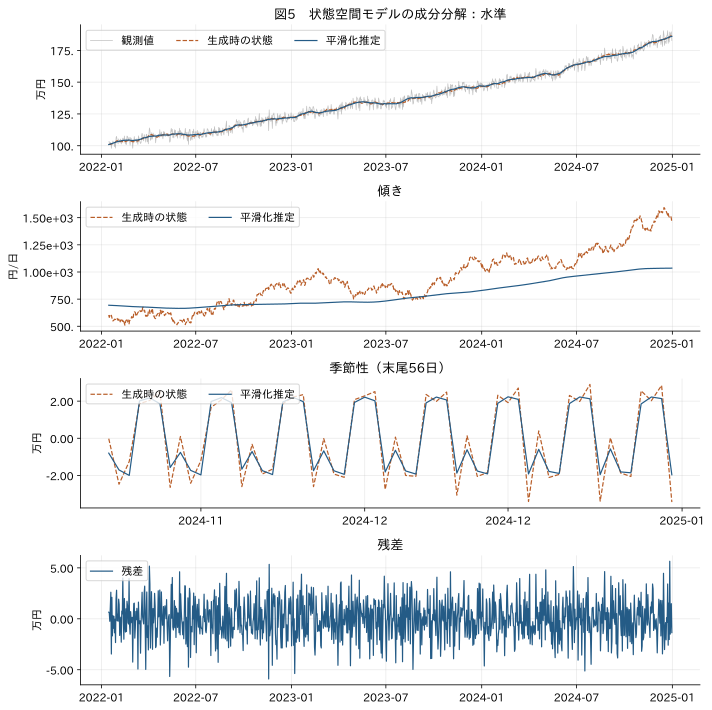

In [7]:
decomposition = pd.DataFrame({
    "水準": result.level.smoothed,
    "傾き": result.trend.smoothed,
    "季節性": result.seasonal.smoothed,
}, index=dates)
decomposition["残差"] = ts - decomposition["水準"] - decomposition["季節性"]
visible = decomposition.iloc[14:]

fig, axes = plt.subplots(4, 1, figsize=(10, 10))
for ax, component, truth, unit, divisor in zip(
    axes, ["水準", "傾き", "季節性", "残差"],
    [level, slope, seasonal, None],
    ["万円", "円/日", "万円", "万円"], [10_000, 1, 10_000, 10_000],
):
    # 週周期が読めるよう、季節性だけ最後の8週間を拡大する。
    start = len(dates) - 56 if component == "季節性" else 14
    if component == "水準":
        ax.plot(dates[start:], ts.iloc[start:] / divisor,
                color=GRAY, alpha=0.450, lw=0.700, label="観測値")
    if truth is not None:
        ax.plot(dates[start:], truth[start:] / divisor,
                color=ORANGE, ls="--", lw=1.20, label="生成時の状態")
    ax.plot(dates[start:], decomposition[component].iloc[start:] / divisor,
            color=BLUE, lw=1.20, label="平滑化推定" if truth is not None else "残差")
    ax.set(title=component + ("（末尾56日）" if component == "季節性" else ""),
           ylabel=unit)
    ax.legend(loc="upper left", ncol=3)
    date_axis(ax)
axes[0].set_title("図5　状態空間モデルの成分分解：水準")
save_svg(fig, "05_ssm_components.svg")

水準の増加と、増加ペースである傾きは分けて読む。各成分の標準偏差を観測値の標準偏差で割ると変動幅を比較できるが、合計が100％になる寄与率ではない。

     標準偏差（円）  観測値との標準偏差比（%）
水準  2.31e+05           99.4
季節性 1.65e+04           7.10
残差  1.89e+04           8.16


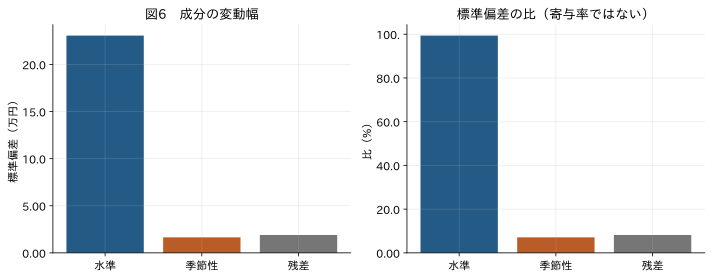

In [8]:
component_sd = visible[["水準", "季節性", "残差"]].std()
sd_ratio = 100 * component_sd / ts.iloc[14:].std()
print(pd.DataFrame({"標準偏差（円）": component_sd,
                    "観測値との標準偏差比（%）": sd_ratio}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(component_sd.index, component_sd / 10_000,
            color=[BLUE, ORANGE, GRAY])
axes[0].set(title="図6　成分の変動幅", ylabel="標準偏差（万円）")
axes[1].bar(sd_ratio.index, sd_ratio, color=[BLUE, ORANGE, GRAY])
axes[1].set(title="標準偏差の比（寄与率ではない）", ylabel="比（%）")
save_svg(fig, "06_component_variation.svg")

モデルの診断には、平滑化残差と区別して標準化した1期先予測誤差を使う。ヒストグラムとQQプロットで分布、自己相関図とLjung–Box検定で時間方向の関係を確認する。問題が見つからなくても、将来の予測精度が保証されるわけではない。

<IPython.core.display.Latex object>

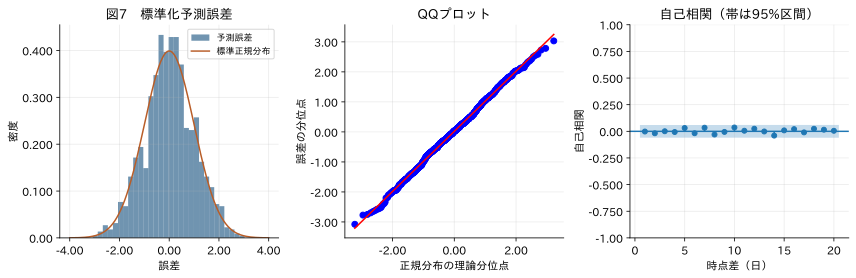

{'7日差までのp値': '0.875', '14日差までのp値': '0.888', '20日差までのp値': '0.975'}


In [9]:
display(Latex(
    r"\(\displaystyle e_t^{\mathrm{std}}="
    r"\frac{y_t-\hat y_{t\mid t-1}}{\sqrt{F_t}},\quad"
    r"F_t=\mathrm{Var}(y_t\mid y_1,\ldots,y_{t-1})\)"
))
diagnostic_start = max(result.loglikelihood_burn,
                       result.filter_results.nobs_diffuse)
standardized = result.filter_results.standardized_forecasts_error[0, diagnostic_start:]
standardized = standardized[np.isfinite(standardized)]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(standardized, bins=30, density=True,
             color=BLUE, alpha=0.650, label="予測誤差")
grid = np.linspace(-4, 4, 200)
axes[0].plot(grid, stats.norm.pdf(grid), color=ORANGE, label="標準正規分布")
axes[0].set(title="図7　標準化予測誤差", xlabel="誤差", ylabel="密度")
axes[0].legend(fontsize=9)
stats.probplot(standardized, dist="norm", plot=axes[1])
axes[1].set(title="QQプロット", xlabel="正規分布の理論分位点", ylabel="誤差の分位点")
plot_acf(standardized, lags=20, zero=False, ax=axes[2], alpha=0.0500)
axes[2].set(title="自己相関（帯は95%区間）", xlabel="時点差（日）", ylabel="自己相関")
for ax in axes[:2]:
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
save_svg(fig, "07_prediction_error_diagnostics.svg")

# statsmodelsと同じ初期期間の扱いでLjung–Box検定を行う。
lb = result.test_serial_correlation(method="ljungbox", lags=[7, 14, 20])[0]
pprint({f"{lag}日差までのp値": sig3(value)
        for lag, value in zip([7, 14, 20], lb[1])}, sort_dicts=False)

### 4.4 予測区間付きの長期予測

推定パラメータを固定したとき、観測値の予測分散は、状態の予測共分散$\mathbf{P}$を観測行列$\mathbf{Z}$で写した分散に、観測ノイズの分散$r$を足す。水準と傾きの不確かさが積み重なるため、遠い将来ほど区間が広がる。

<IPython.core.display.Latex object>

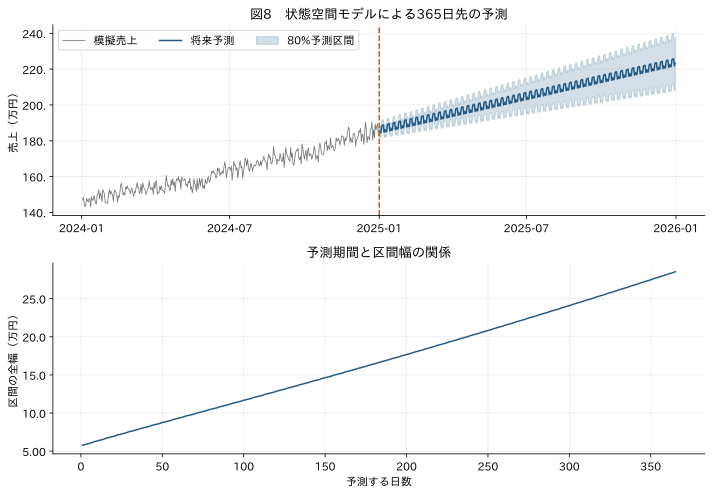

{'30日先の区間全幅（万円）': '7.56',
 '90日先の区間全幅（万円）': '11.1',
 '180日先の区間全幅（万円）': '16.4',
 '365日先の区間全幅（万円）': '28.5'}


In [10]:
display(Latex(
    r"\(\displaystyle \mathrm{Var}(y_{T+h}\mid y_1,\ldots,y_T)="
    r"\mathbf{Z}\mathbf{P}_{T+h\mid T}\mathbf{Z}^{\top}+r\)"
))
prediction = result.get_forecast(steps=365)
mean = prediction.predicted_mean
interval = prediction.conf_int(alpha=0.200)
width = interval.iloc[:, 1] - interval.iloc[:, 0]

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].plot(ts.index[-365:], ts.iloc[-365:] / 10_000,
             color=GRAY, lw=0.800, label="模擬売上")
axes[0].plot(mean.index, mean / 10_000, color=BLUE, label="将来予測")
axes[0].fill_between(mean.index, interval.iloc[:, 0] / 10_000,
                     interval.iloc[:, 1] / 10_000,
                     color=BLUE, alpha=0.200, label="80%予測区間")
axes[0].axvline(mean.index[0], color=ORANGE, ls="--")
axes[0].set(title="図8　状態空間モデルによる365日先の予測", ylabel="売上（万円）")
axes[0].legend(loc="upper left", ncol=3)
date_axis(axes[0])
axes[1].plot(np.arange(1, 366), width / 10_000, color=BLUE)
axes[1].set(xlabel="予測する日数", ylabel="区間の全幅（万円）",
            title="予測期間と区間幅の関係")
save_svg(fig, "08_ssm_forecast.svg")

pprint({f"{h}日先の区間全幅（万円）": sig3(width.iloc[h - 1] / 10_000)
        for h in [30, 90, 180, 365]}, sort_dicts=False)

この区間はモデルの仮定と推定したパラメータに基づくもので、将来の構造変化をすべて含むわけではない。仕入れや人員配置では点予測だけで決めず、上振れ・下振れも考慮する。

## 結論

この記事では、売上を成分に分け、Prophetと状態空間モデルで予測と潜在状態の推定を行う手順を紹介した。

季節性と水準の変化を分け、未学習期間の誤差と予測区間を確認することが基本となる。施策の効果を確かめるには、施策を行わなかった場合との比較が別途必要である。

[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)では、変化点の表現、状態空間モデルの行列表現、カルマンフィルタ、結果の読み方を本文で詳しく扱っている。章全体のコードは[サポートページ](https://github.com/gihyo-book/marketing_science_book)で参照できる。